# 08 — Fase 2: Cadeia de Evidências, Especialização dos Agentes e Business Case

Este notebook responde diretamente ao feedback da Fase 1:

| Feedback da banca | O que este notebook entrega |
|---|---|
| *"Detalhar o racional de onde partiram os achados"* | **Cadeia de evidência**: pergunta → dado (tabela/coluna) → método → resultado → decisão |
| *"Ações dos agentes muito amplas, carecendo de especialização"* | Evidências que **estreitam o escopo** de cada agente (gatilhos e públicos específicos) |
| *"Múltiplos objetivos — priorizar o que tem maior proximidade com o negócio"* | **Matriz de priorização** dos 6 agentes → 3 selecionados |
| *"Falha de revisão"* | **Fonte única de números** (`fase2/dados/numeros_fase2.json`) com definições |

Todos os números do Relatório Fase 2 saem daqui.

In [1]:
import pandas as pd, numpy as np, json, unicodedata, re, warnings
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings('ignore')

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
D = ROOT / 'data' / 'olist'
IMG = ROOT / 'fase2' / 'img'; IMG.mkdir(parents=True, exist_ok=True)
DADOS = ROOT / 'fase2' / 'dados'; DADOS.mkdir(parents=True, exist_ok=True)
EXEMPLOS = ROOT / 'fase2' / 'prompts' / 'exemplos'; EXEMPLOS.mkdir(parents=True, exist_ok=True)

# Paleta (validada, modo claro, impressão): azul = série principal, laranja = destaque
AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#b9b8b2'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.dpi': 200,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
})
def br(v, n=1): return f'{v:.{n}f}'.replace('.', ',')
def salvar(fig, nome):
    fig.tight_layout(); fig.savefig(IMG / nome, bbox_inches='tight'); plt.show()

N = {}  # dicionário de números oficiais
def reg(chave, valor, definicao, fonte):
    N[chave] = {'valor': valor, 'definicao': definicao, 'fonte': fonte}
    return valor

## 1. Carga e base de pedidos entregues

In [2]:
dt = ['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
      'order_delivered_customer_date','order_estimated_delivery_date']
o  = pd.read_csv(D/'olist_orders_dataset.csv', parse_dates=dt)
c  = pd.read_csv(D/'olist_customers_dataset.csv')
it = pd.read_csv(D/'olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])
rv = pd.read_csv(D/'olist_order_reviews_dataset.csv', parse_dates=['review_creation_date','review_answer_timestamp'])
pay= pd.read_csv(D/'olist_order_payments_dataset.csv')
pr = pd.read_csv(D/'olist_products_dataset.csv')
se = pd.read_csv(D/'olist_sellers_dataset.csv')
tr = pd.read_csv(D/'product_category_name_translation.csv')

o = o.merge(c, on='customer_id')
valor = pay.groupby('order_id').payment_value.sum().rename('valor_pedido')
o = o.join(valor, on='order_id')

d = o[(o.order_status=='delivered') & o.order_delivered_customer_date.notna()].copy()
d['dias_entrega'] = (d.order_delivered_customer_date - d.order_purchase_timestamp).dt.total_seconds()/86400
d['dias_proc']    = (d.order_delivered_carrier_date - d.order_purchase_timestamp).dt.total_seconds()/86400
d['dias_transito']= (d.order_delivered_customer_date - d.order_delivered_carrier_date).dt.total_seconds()/86400
d['atrasado']     = d.order_delivered_customer_date > d.order_estimated_delivery_date
lim = it.groupby('order_id').shipping_limit_date.max()
d = d.join(lim, on='order_id')
d['postagem_atrasada'] = d.order_delivered_carrier_date > d.shipping_limit_date

reg('pedidos_total', int(len(o)), 'Pedidos no dataset (todas as situações)', 'orders')
reg('pedidos_entregues', int(len(d)), 'Pedidos com status delivered e data de entrega', 'orders')
reg('receita_total', round(float(pay.payment_value.sum()),2), 'Soma de payment_value', 'order_payments')
reg('ticket_medio', round(float(valor.mean()),2), 'Valor médio pago por pedido', 'order_payments')
reg('dias_entrega_medio', round(float(d.dias_entrega.mean()),2),
    'Média (dias corridos fracionados) entre compra e entrega, pedidos entregues. Substitui o 12,47 da Fase 1.', 'orders')
reg('dias_transito_medio', round(float(d.dias_transito.mean()),2), 'Média entre postagem (delivered_carrier) e entrega', 'orders')
reg('dias_proc_medio', round(float(d.dias_proc.mean()),2), 'Média entre compra e postagem (processamento do seller)', 'orders')
reg('pct_transito', round(float(d.dias_transito.mean()/d.dias_entrega.mean()*100),1), '% do tempo total gasto em trânsito', 'orders')
reg('taxa_atraso', round(float(d.atrasado.mean()*100),2), '% de pedidos entregues após order_estimated_delivery_date', 'orders')
{k:v['valor'] for k,v in N.items()}

{'pedidos_total': 99441,
 'pedidos_entregues': 96470,
 'receita_total': 16008872.12,
 'ticket_medio': 160.99,
 'dias_entrega_medio': 12.56,
 'dias_transito_medio': 9.33,
 'dias_proc_medio': 3.23,
 'pct_transito': 74.3,
 'taxa_atraso': 8.11}

## 2. Cadeia de evidência — LogiPredict
**Pergunta:** onde o atraso nasce e quanto ele custa em satisfação?

In [3]:
r1 = rv.sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last')
m = d.merge(r1[['order_id','review_id','review_score','review_comment_title','review_comment_message']], on='order_id')

nota_atr, nota_ok = m[m.atrasado].review_score.mean(), m[~m.atrasado].review_score.mean()
neg_atr, neg_ok = (m[m.atrasado].review_score<=2).mean(), (m[~m.atrasado].review_score<=2).mean()
reg('nota_media_atrasado', round(float(nota_atr),2), 'Nota média de pedidos entregues com atraso', 'orders+reviews')
reg('nota_media_no_prazo', round(float(nota_ok),2), 'Nota média de pedidos entregues no prazo', 'orders+reviews')
reg('pct_neg_atrasado', round(float(neg_atr*100),1), '% de notas 1–2 em pedidos atrasados', 'orders+reviews')
reg('pct_neg_no_prazo', round(float(neg_ok*100),1), '% de notas 1–2 em pedidos no prazo', 'orders+reviews')

pa = d.postagem_atrasada.mean()
atr_pa, atr_po = d[d.postagem_atrasada].atrasado.mean(), d[~d.postagem_atrasada].atrasado.mean()
reg('pct_postagem_atrasada', round(float(pa*100),1), '% de pedidos em que o seller postou após shipping_limit_date', 'orders+order_items')
reg('atraso_se_postagem_atrasada', round(float(atr_pa*100),1), 'Taxa de atraso quando a postagem foi após o limite', 'orders+order_items')
reg('atraso_se_postagem_no_prazo', round(float(atr_po*100),1), 'Taxa de atraso quando a postagem foi no prazo', 'orders+order_items')
reg('pct_atrasos_com_postagem_atrasada', round(float(d[d.atrasado].postagem_atrasada.mean()*100),1),
    '% dos pedidos atrasados que tiveram postagem atrasada pelo seller', 'orders+order_items')

antec = (d[d.atrasado].order_estimated_delivery_date - d[d.atrasado].order_delivered_carrier_date).dt.total_seconds()/86400
reg('mediana_dias_postagem_ate_prazo_atrasados', round(float(antec.median()),1),
    'Nos pedidos que atrasaram: mediana de dias entre a postagem e o prazo prometido (janela para agir)', 'orders')
uf = d.groupby('customer_state').atrasado.agg(['mean','size']).sort_values('mean', ascending=False)
reg('atraso_top_uf', {k: round(float(v*100),1) for k,v in uf['mean'].head(5).items()}, 'UFs de destino com maior taxa de atraso', 'orders+customers')
print(f'Atrasado: nota {nota_atr:.2f} | {neg_atr:.1%} notas 1-2   ·   No prazo: nota {nota_ok:.2f} | {neg_ok:.1%} notas 1-2')
print(f'Postagem atrasada em {pa:.1%} dos pedidos → atraso {atr_pa:.1%} vs {atr_po:.1%} ({atr_pa/atr_po:.1f}x)')
uf.head(10)

Atrasado: nota 2.57 | 54.1% notas 1-2   ·   No prazo: nota 4.29 | 9.2% notas 1-2
Postagem atrasada em 9.0% dos pedidos → atraso 24.4% vs 6.5% (3.8x)


,mean,size
customer_state,,
AL,0.239295,397
MA,0.196653,717
PI,0.159664,476
CE,0.153245,1279
SE,0.152239,335
BA,0.140356,3256
RJ,0.134737,12350
TO,0.127737,274
PA,0.123679,946


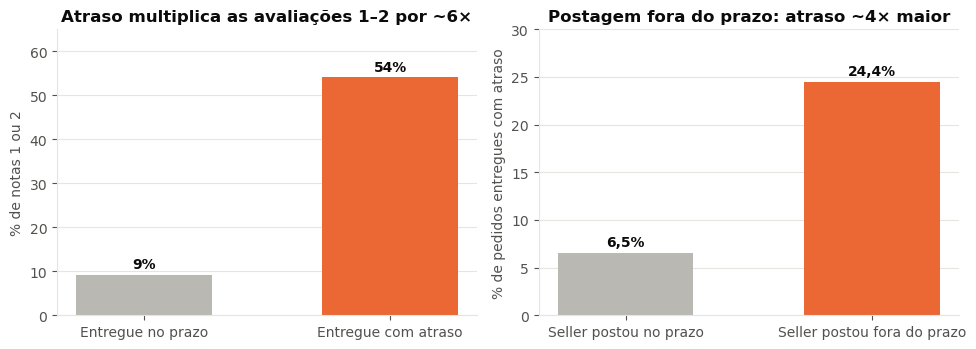

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axs[0]
vals = [neg_ok*100, neg_atr*100]
ax.bar(['Entregue no prazo','Entregue com atraso'], vals, color=[CINZA, LARANJA], width=0.55)
for i,v in enumerate(vals): ax.text(i, v+1.5, f'{v:.0f}%', ha='center', color=INK, fontweight='bold')
ax.set_title('Atraso multiplica as avaliações 1–2 por ~6×'); ax.set_ylabel('% de notas 1 ou 2'); ax.set_ylim(0, 65); ax.grid(axis='x', visible=False)
ax = axs[1]
vals = [atr_po*100, atr_pa*100]
ax.bar(['Seller postou no prazo','Seller postou fora do prazo'], vals, color=[CINZA, LARANJA], width=0.55)
for i,v in enumerate(vals): ax.text(i, v+0.8, f'{br(v)}%', ha='center', color=INK, fontweight='bold')
ax.set_title('Postagem fora do prazo: atraso ~4× maior'); ax.set_ylabel('% de pedidos entregues com atraso'); ax.set_ylim(0, 30); ax.grid(axis='x', visible=False)
salvar(fig, 'f2_evidencia_atraso.png')

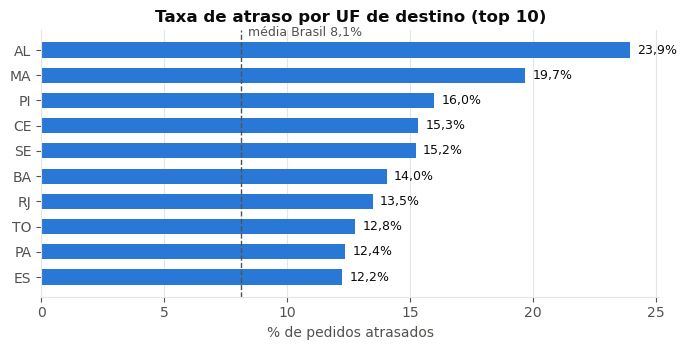

In [5]:
top = uf.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(top.index, top['mean']*100, color=AZUL, height=0.6)
ax.axvline(d.atrasado.mean()*100, color=INK2, lw=1, ls='--')
ax.text(d.atrasado.mean()*100+0.3, len(top)-0.45, f'média Brasil {br(d.atrasado.mean()*100)}%', color=INK2, fontsize=9)
for y,v in enumerate(top['mean']*100): ax.text(v+0.3, y, f'{br(v)}%', va='center', fontsize=9, color=INK)
ax.set_title('Taxa de atraso por UF de destino (top 10)'); ax.set_xlabel('% de pedidos atrasados'); ax.grid(axis='y', visible=False)
salvar(fig, 'f2_atraso_uf.png')

## 3. Cadeia de evidência — SentimentDesk
**Pergunta:** do que reclamam os clientes insatisfeitos? A taxonomia abaixo vira a lista de **motivos** que o agente classifica.

> Método: classificação por regras (palavras-chave normalizadas, sem acento) sobre título+comentário das avaliações 1–2 com texto.
> É um **baseline transparente** para calibrar o agente; o LLM do SentimentDesk faz a classificação real.

> ⚠️ **Correção de rigor vs. Fase 1:** `review_answer_timestamp` é a data em que o **cliente respondeu a pesquisa**, não o tempo de resposta da Olist.
> O "tempo de resposta de 3,15 dias" da Fase 1 foi reinterpretado: o dataset **não** contém o SLA de atendimento — ele vira **baseline a medir no piloto**.

In [6]:
def norm(s):
    s = unicodedata.normalize('NFKD', str(s).lower())
    return ''.join(ch for ch in s if not unicodedata.combining(ch))

neg = rv[rv.review_score<=2].copy()
neg['txt'] = (neg.review_comment_title.fillna('')+' '+neg.review_comment_message.fillna('')).map(norm).str.strip()
reg('reviews_total', int(len(rv)), 'Avaliações no dataset', 'order_reviews')
reg('pct_nota_1', round(float((rv.review_score==1).mean()*100),1), '% de avaliações nota 1', 'order_reviews')
reg('pct_nota_1_2', round(float((rv.review_score<=2).mean()*100),1), '% de avaliações nota 1 ou 2', 'order_reviews')
reg('reviews_negativas', int(len(neg)), 'Avaliações nota 1–2', 'order_reviews')
negt = neg[neg.txt!=''].copy()
reg('reviews_negativas_com_texto', int(len(negt)), 'Avaliações nota 1–2 com título ou comentário', 'order_reviews')

REGRAS = [  # (motivo, grupo executivo, regex) — ordem = prioridade
 ('Não recebido', 'Entrega', r'nao (?:recebi|chegou|foi entregue|entreg|veio)|ainda nao|aguardando|cade|ate (?:agora|o momento|hoje)|nunca chegou|sem (?:ter )?receb|nao recebemos'),
 ('Item faltando', 'Pedido incorreto', r'falt|veio (?:apenas|so|somente)|so (?:veio|recebi|chegou|foi entregue)|recebi (?:apenas|somente|so)|incomplet|metade|um dos|uma das|1 dos|1 das|apenas (?:um|1|uma)'),
 ('Produto errado/diferente', 'Pedido incorreto', r'errad|diferente|outro produto|nao (?:era|e) o|trocad|nao corresponde|nao condiz|amostra'),
 ('Defeito/avaria', 'Produto', r'defeit|quebr|danific|nao funciona|parou de funcionar|deixar de funcionar|estragad|rasgad|amassad|avariad|vazad'),
 ('Atraso', 'Entrega', r'atras|prazo|demor|lent|pontual|data marcada|chegasse'),
 ('Qualidade/expectativa', 'Produto', r'qualidade|ruim|pessim|horrivel|fragil|falsific|original|pequen|fraco|nao gostei|decepc'),
 ('Atendimento/estorno', 'Atendimento e financeiro', r'atendimento|resposta|respond|contato|estorno|reembols|devol|cancel|dinheiro|cobra|sac|informac|frete'),
]
def motivo(t):
    for nome, grupo, rx in REGRAS:
        if re.search(rx, t): return nome, grupo
    return 'Outros/genérico', 'Outros'
negt[['motivo','grupo']] = negt.txt.apply(lambda t: pd.Series(motivo(t)))
mot = negt.motivo.value_counts(normalize=True)*100
grp = negt.grupo.value_counts(normalize=True)*100
reg('motivos_reviews_negativas', {k: round(float(v),1) for k,v in mot.items()}, 'Motivo principal (regras) em reviews 1–2 com texto', 'order_reviews')
reg('grupos_reviews_negativas', {k: round(float(v),1) for k,v in grp.items()}, 'Grupo executivo do motivo principal', 'order_reviews')

neg_m = m[m.review_score<=2]
reg('pct_neg_em_pedido_atrasado', round(float(neg_m.atrasado.mean()*100),1), '% das notas 1–2 (pedidos entregues) cujo pedido atrasou', 'orders+reviews')

per = (rv.review_creation_date >= '2017-09-01') & (rv.review_creation_date < '2018-09-01')
reg('reviews_negativas_12m', int(((rv.review_score<=2) & per).sum()), 'Avaliações 1–2 criadas entre set/2017 e ago/2018', 'order_reviews')
grp.round(1), mot.round(1)

(grupo
 Entrega                     46.7
 Outros                      17.8
 Pedido incorreto            17.8
 Produto                     12.3
 Atendimento e financeiro     5.4
 Name: proportion, dtype: float64,
 motivo
 Não recebido                39.5
 Outros/genérico             17.8
 Item faltando               10.4
 Produto errado/diferente     7.4
 Qualidade/expectativa        7.2
 Atraso                       7.1
 Atendimento/estorno          5.4
 Defeito/avaria               5.1
 Name: proportion, dtype: float64)

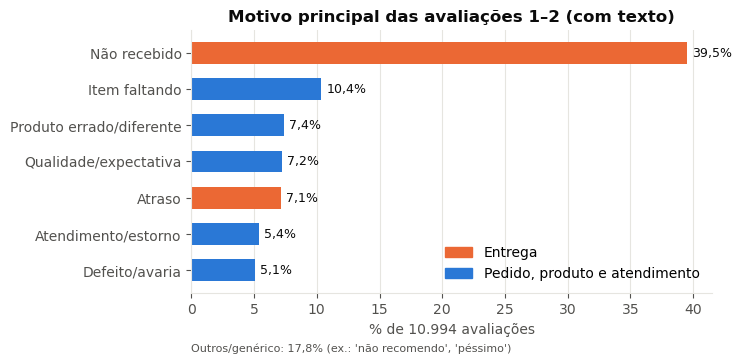

In [7]:
ordem = mot.drop('Outros/genérico').sort_values()
cores = {'Entrega': LARANJA}
grupo_de = {n:g for n,g,_ in REGRAS}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(ordem.index, ordem.values, color=[cores.get(grupo_de[n], AZUL) for n in ordem.index], height=0.6)
for y,v in enumerate(ordem.values): ax.text(v+0.4, y, f'{br(v)}%', va='center', fontsize=9, color=INK)
ax.set_title('Motivo principal das avaliações 1–2 (com texto)'); ax.set_xlabel(f'% de {len(negt):,} avaliações'.replace(',', '.'))
ax.grid(axis='y', visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=LARANJA, label='Entrega'), Patch(color=AZUL, label='Pedido, produto e atendimento')], frameon=False, loc='lower right')
ax.text(0, -0.22, f"Outros/genérico: {br(mot['Outros/genérico'])}% (ex.: 'não recomendo', 'péssimo')", transform=ax.transAxes, fontsize=8, color=INK2)
salvar(fig, 'f2_motivos_reviews.png')

## 4. Cadeia de evidência — WinBack (especializado em **2ª compra**)
**Pergunta:** quando o cliente volta — e o que diferencia quem volta?
Na Fase 1 o público era a base "Em Risco" (inativa há +439 dias). Os dados abaixo mostram que **a recompra acontece cedo**: o agente é especializado na **janela pós-1ª compra**.

In [8]:
oe = o[o.order_status=='delivered'].sort_values('order_purchase_timestamp')
n_ped = oe.groupby('customer_unique_id').order_id.count()
reg('clientes_unicos', int(len(n_ped)), 'customer_unique_id com ao menos 1 pedido entregue', 'orders+customers')
reg('taxa_recompra', round(float((n_ped>1).mean()*100),2), '% de clientes únicos com 2+ pedidos entregues', 'orders+customers')

prim = oe.drop_duplicates('customer_unique_id')[['customer_unique_id','order_id','order_purchase_timestamp','valor_pedido']]
seg = (oe[oe.duplicated('customer_unique_id')].drop_duplicates('customer_unique_id')
       [['customer_unique_id','order_purchase_timestamp','valor_pedido']]
       .rename(columns={'order_purchase_timestamp':'t2','valor_pedido':'valor2'}))
fs = prim.merge(seg, on='customer_unique_id', how='left')
fs['gap'] = (fs.t2 - fs.order_purchase_timestamp).dt.days
rep = fs[fs.gap >= 1]   # exclui mesmo dia (pedidos divididos no checkout)
reg('recompras_validas', int(len(rep)), 'Clientes com 2ª compra em dia diferente da 1ª', 'orders')
reg('mediana_dias_2a_compra', int(rep.gap.median()), 'Mediana de dias entre 1ª e 2ª compra (gap ≥ 1 dia)', 'orders')
for j in (30, 60, 90, 180):
    reg(f'pct_2a_compra_ate_{j}d', round(float((rep.gap<=j).mean()*100),1), f'% das 2ªs compras que ocorrem em até {j} dias', 'orders')
reg('ticket_2a_compra', round(float(rep.valor2.mean()),2), 'Valor médio da 2ª compra', 'orders+payments')

# experiência da 1ª compra x recompra
fe = fs.merge(m[['order_id','atrasado','review_score']], on='order_id', how='left')
fe['voltou'] = fe.gap >= 1
reg('recompra_1a_atrasada', round(float(fe[fe.atrasado==True].voltou.mean()*100),2), 'Recompra quando a 1ª compra atrasou', 'orders+reviews')
reg('recompra_1a_no_prazo', round(float(fe[fe.atrasado==False].voltou.mean()*100),2), 'Recompra quando a 1ª compra chegou no prazo', 'orders+reviews')

# categoria da 1ª compra x recompra (público e recomendação do agente)
cat = it.drop_duplicates('order_id')[['order_id','product_id']].merge(pr[['product_id','product_category_name']], on='product_id')
fe = fe.merge(cat[['order_id','product_category_name']], on='order_id', how='left')
cr = fe.groupby('product_category_name').voltou.agg(['mean','size']).query('size>=1000').sort_values('mean', ascending=False)
reg('recompra_top_categorias', {k: round(float(v*100),1) for k,v in cr['mean'].head(5).items()}, 'Categorias da 1ª compra com maior recompra (≥1.000 clientes)', 'orders+items+products')
print(f"Mediana {rep.gap.median():.0f} dias | até 90d: {(rep.gap<=90).mean():.1%} | recompra 1ª atrasada {N['recompra_1a_atrasada']['valor']}% vs no prazo {N['recompra_1a_no_prazo']['valor']}%")
cr.head(8)

Mediana 76 dias | até 90d: 54.4% | recompra 1ª atrasada 1.56% vs no prazo 2.13%


,mean,size
product_category_name,,
fashion_bolsas_e_acessorios,0.036073,1691
moveis_decoracao,0.027164,5927
esporte_lazer,0.026656,7203
cama_mesa_banho,0.026225,8732
pet_shop,0.025153,1630
ferramentas_jardim,0.024310,3332
perfumaria,0.023762,2988
telefonia,0.021303,3990


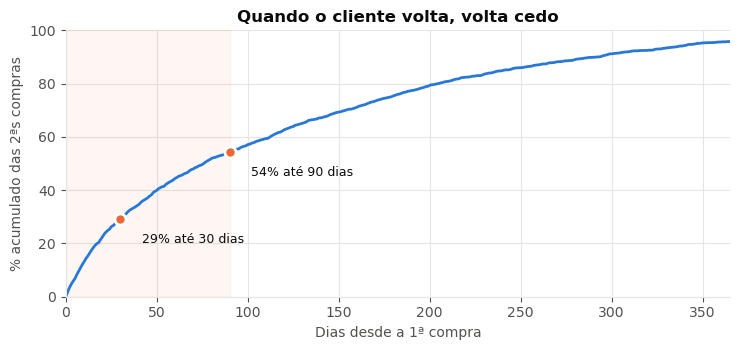

In [9]:
x = np.arange(0, 366)
cum = [(rep.gap<=k).mean()*100 for k in x]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(x, cum, color=AZUL, lw=2)
for k in (30, 90):
    v = (rep.gap<=k).mean()*100
    ax.plot([k], [v], 'o', color=LARANJA, ms=8, mec='white', mew=2)
    ax.annotate(f'{v:.0f}% até {k} dias', (k, v), xytext=(k+12, v-9), fontsize=9, color=INK)
ax.axvspan(0, 90, color=LARANJA, alpha=0.06)
ax.set_xlim(0, 365); ax.set_ylim(0, 100)
ax.set_title('Quando o cliente volta, volta cedo'); ax.set_xlabel('Dias desde a 1ª compra'); ax.set_ylabel('% acumulado das 2ªs compras')
salvar(fig, 'f2_janela_2a_compra.png')

## 5. Matriz de priorização — por que 3 agentes (e quais)
Critérios (1–5): **Impacto no negócio** (tamanho da dor comprovada), **Proximidade do core** (jornada do pedido: compra → entrega → avaliação → recompra),
**Evidência nos dados** (achado quantificado no dataset), **Viabilidade** (dados disponíveis hoje, baixa integração), **Risco** (inverso: 5 = baixo risco).

In [10]:
crit = ['Impacto','Proximidade do core','Evidência nos dados','Viabilidade','Risco (inverso)']
pesos = np.array([0.30, 0.25, 0.20, 0.15, 0.10])
notas = pd.DataFrame({
 'LogiPredict':   [5,5,5,4,4],
 'SentimentDesk': [4,5,5,5,4],
 'WinBack':       [5,4,4,4,3],
 'SellerCare':    [4,3,4,3,2],
 'SmartFreight':  [3,3,3,2,2],
 'Maestro':       [3,2,2,2,3],
}, index=crit).T
notas['Score ponderado'] = (notas[crit].values * pesos).sum(axis=1).round(2)
notas = notas.sort_values('Score ponderado', ascending=False)
notas['Decisão Fase 2'] = ['Detalhar']*3 + ['Absorvido/backlog']*3
reg('priorizacao', notas['Score ponderado'].to_dict(), 'Score ponderado (pesos 30/25/20/15/10)', 'avaliação do grupo')
notas

,Impacto,Proximidade do core,Evidência nos dados,Viabilidade,Risco (inverso),Score ponderado,Decisão Fase 2
LogiPredict,5,5,5,4,4,4.75,Detalhar
SentimentDesk,4,5,5,5,4,4.60,Detalhar
WinBack,5,4,4,4,3,4.20,Detalhar
SellerCare,4,3,4,3,2,3.40,Absorvido/backlog
SmartFreight,3,3,3,2,2,2.75,Absorvido/backlog
Maestro,3,2,2,2,3,2.40,Absorvido/backlog


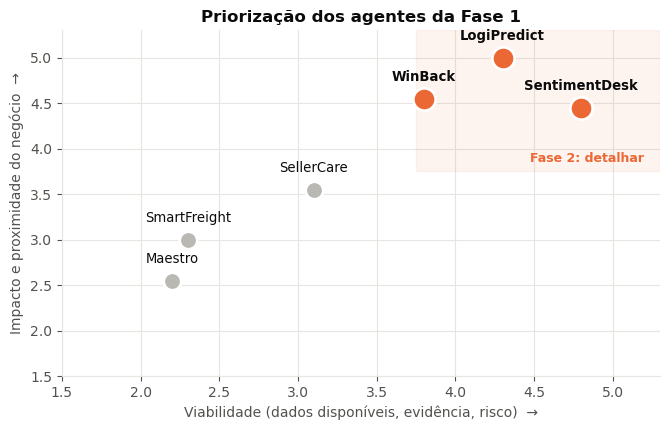

In [11]:
imp = notas['Impacto']*0.55 + notas['Proximidade do core']*0.45
via = notas['Viabilidade']*0.5 + notas['Evidência nos dados']*0.3 + notas['Risco (inverso)']*0.2
fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.axhspan(3.75, 5.3, xmin=(3.75-1.5)/3.8, color=LARANJA, alpha=0.07)
ax.text(5.2, 3.82, 'Fase 2: detalhar', ha='right', va='bottom', color=LARANJA, fontweight='bold', fontsize=9)
for nome in notas.index:
    sel = notas.loc[nome,'Decisão Fase 2']=='Detalhar'
    ax.scatter(via[nome], imp[nome], s=260 if sel else 160, color=LARANJA if sel else CINZA, edgecolor='white', linewidth=2, zorder=3)
    ax.annotate(nome, (via[nome], imp[nome]), xytext=(0, 13), textcoords='offset points', ha='center', fontsize=9.5,
                color=INK, fontweight='bold' if sel else 'normal')
ax.set_xlim(1.5, 5.3); ax.set_ylim(1.5, 5.3)
ax.set_xlabel('Viabilidade (dados disponíveis, evidência, risco)  →'); ax.set_ylabel('Impacto e proximidade do negócio  →')
ax.set_title('Priorização dos agentes da Fase 1')
salvar(fig, 'f2_priorizacao.png')

## 6. Business case — cenários (janela de 12 meses: set/2017–ago/2018)
Premissas explícitas, três cenários. São **hipóteses a validar em piloto** (dataset histórico 2016–2018 e amostra da operação).

In [12]:
P0, P1 = '2017-09-01', '2018-09-01'
dd = d[(d.order_purchase_timestamp>=P0)&(d.order_purchase_timestamp<P1)]
ped12 = len(dd); post_atr12 = int(dd.postagem_atrasada.sum())
atr_pa12 = dd[dd.postagem_atrasada].atrasado.mean(); atr_po12 = dd[~dd.postagem_atrasada].atrasado.mean()
# o cálculo usa as taxas ARREDONDADAS (1 casa, em %) que aparecem no relatório → qualquer pessoa refaz a conta à mão
gap_atr = (round(atr_pa12*100,1) - round(atr_po12*100,1)) / 100
reg('bc_atraso_se_postagem_atrasada_12m', round(float(atr_pa12*100),1), 'Janela set/17–ago/18: atraso quando a postagem foi após o limite', 'orders+order_items')
reg('bc_atraso_se_postagem_no_prazo_12m', round(float(atr_po12*100),1), 'Janela set/17–ago/18: atraso quando a postagem foi no prazo', 'orders+order_items')
delta_neg = (round(neg_atr*100,1) - round(neg_ok*100,1)) / 100
cen = {'Conservador':0.25, 'Base':0.50, 'Otimista':0.75}
logi = {k: {'atrasos_evitados': round(post_atr12*gap_atr*f), 'notas_1_2_evitadas': round(post_atr12*gap_atr*f*delta_neg)} for k,f in cen.items()}

# SentimentDesk: produtividade da triagem + resposta
MIN_MANUAL, MIN_AGENTE, CUSTO_HORA = 12, 3, 45.0   # premissas: minutos por caso e custo/hora do analista
neg12 = N['reviews_negativas_12m']['valor']
cob = {'Conservador':0.5, 'Base':0.7, 'Otimista':0.9}  # % dos casos tratados com apoio do agente
senti = {k: {'horas_poupadas': round(neg12*f*(MIN_MANUAL-MIN_AGENTE)/60),
             'reais_poupados': round(neg12*f*(MIN_MANUAL-MIN_AGENTE)/60*CUSTO_HORA, 0)} for k,f in cob.items()}

# WinBack: novos clientes no período x aumento da conversão em 2ª compra (90 dias)
novos12 = int(((prim.order_purchase_timestamp>=P0)&(prim.order_purchase_timestamp<P1)).sum())
base90 = float(((fs.gap>=1)&(fs.gap<=90)).sum()/len(fs))
upl = {'Conservador':0.0025, 'Base':0.005, 'Otimista':0.010}   # pontos percentuais absolutos
tk2 = N['ticket_2a_compra']['valor']
win = {k: {'segundas_compras_extra': round(novos12*u), 'receita_extra': round(novos12*u*tk2, 0)} for k,u in upl.items()}

reg('bc_pedidos_12m', ped12, 'Pedidos entregues set/2017–ago/2018', 'orders')
reg('bc_postagens_atrasadas_12m', post_atr12, 'Pedidos com postagem atrasada no período', 'orders+items')
reg('bc_novos_clientes_12m', novos12, '1ª compra entregue no período', 'orders')
reg('bc_conversao_2a_compra_90d', round(base90*100,2), '% de clientes com 2ª compra em 1–90 dias', 'orders')
reg('bc_premissas', {'reducao_gap_atraso': cen, 'min_manual': MIN_MANUAL, 'min_agente': MIN_AGENTE, 'custo_hora': CUSTO_HORA,
                     'cobertura_sentiment': cob, 'uplift_pp_2a_compra': upl}, 'Premissas do business case', 'grupo')
reg('bc_logipredict', logi, 'Atrasos e notas 1–2 evitados por ano', 'cálculo')
reg('bc_sentimentdesk', senti, 'Horas e R$ de triagem poupados por ano', 'cálculo')
reg('bc_winback', win, '2ªs compras e receita incremental por ano', 'cálculo')
pd.DataFrame({'LogiPredict': logi, 'SentimentDesk': senti, 'WinBack': win})

,LogiPredict,SentimentDesk,WinBack
Conservador,"{'atrasos_evitados': 336, 'notas_1_2_evitadas'...","{'horas_poupadas': 878, 'reais_poupados': 3952...","{'segundas_compras_extra': 179, 'receita_extra..."
Base,"{'atrasos_evitados': 672, 'notas_1_2_evitadas'...","{'horas_poupadas': 1230, 'reais_poupados': 553...","{'segundas_compras_extra': 358, 'receita_extra..."
Otimista,"{'atrasos_evitados': 1008, 'notas_1_2_evitadas...","{'horas_poupadas': 1581, 'reais_poupados': 711...","{'segundas_compras_extra': 717, 'receita_extra..."


## 7. Casos reais para os exemplos de prompt (entrada dos agentes)

In [13]:
catn = pr.merge(tr, on='product_category_name', how='left')[['product_id','product_category_name']]
item1 = it.drop_duplicates('order_id').merge(catn, on='product_id').merge(se, on='seller_id')
base = m.merge(item1[['order_id','seller_id','seller_state','product_category_name','price','freight_value']], on='order_id')
base['texto'] = (base.review_comment_title.fillna('')+' '+base.review_comment_message.fillna('')).str.strip()
base['txtn'] = base.texto.map(norm)
casos = {'sentimentdesk': [], 'logipredict': [], 'winback': []}
for nome, grupo, rx in REGRAS[:5]:
    cand = base[(base.review_score<=2) & base.txtn.str.contains(rx) & base.texto.str.len().between(60, 220)]
    cand = cand[cand.txtn.apply(lambda t: motivo(t)[0]==nome)]
    r = cand.sample(1, random_state=7).iloc[0]
    casos['sentimentdesk'].append({
        'motivo_baseline': nome, 'review_id': r.review_id, 'order_id': r.order_id, 'nota': int(r.review_score),
        'titulo': r.review_comment_title if isinstance(r.review_comment_title, str) else '',
        'comentario': r.review_comment_message if isinstance(r.review_comment_message, str) else '',
        'categoria': r.product_category_name, 'uf_cliente': r.customer_state, 'uf_seller': r.seller_state,
        'data_compra': str(r.order_purchase_timestamp.date()), 'prazo_estimado': str(r.order_estimated_delivery_date.date()),
        'data_entrega': str(r.order_delivered_customer_date.date()), 'atrasou': bool(r.atrasado),
        'valor_pedido': round(float(r.valor_pedido),2), 'seller_id': r.seller_id})
# LogiPredict: pedidos com postagem atrasada para UF crítica (um atrasou, outro não) + um de baixo risco
lp = d.merge(item1[['order_id','seller_id','seller_state','product_category_name']], on='order_id')
for filtro, seed in [((lp.postagem_atrasada) & lp.customer_state.isin(['AL','MA','PI','CE']) & lp.atrasado, 3),
                     ((lp.postagem_atrasada) & (lp.customer_state=='BA') & ~lp.atrasado, 3),
                     ((~lp.postagem_atrasada) & (lp.customer_state=='SP') & (lp.seller_state=='SP') & ~lp.atrasado, 3)]:
    r = lp[filtro].sample(1, random_state=seed).iloc[0]
    casos['logipredict'].append({
        'order_id': r.order_id, 'seller_id': r.seller_id, 'uf_seller': r.seller_state, 'uf_cliente': r.customer_state,
        'categoria': r.product_category_name, 'data_compra': str(r.order_purchase_timestamp),
        'limite_postagem': str(r.shipping_limit_date), 'data_postagem': str(r.order_delivered_carrier_date),
        'prazo_estimado': str(r.order_estimated_delivery_date.date()),
        'taxa_atraso_uf_destino_pct': round(float(uf.loc[r.customer_state,'mean']*100),1),
        'resultado_real': {'data_entrega': str(r.order_delivered_customer_date.date()), 'atrasou': bool(r.atrasado)}})
# WinBack: clientes cuja 1ª compra foi entregue (no prazo, nota 5) e sem 2ª compra; + um com 1ª compra atrasada
fw = fe.merge(prim[['order_id']], on='order_id').merge(o[['order_id','customer_state','order_delivered_customer_date']], on='order_id')
for filtro, seed in [((fw.review_score==5)&(fw.atrasado==False)&(~fw.voltou)&(fw.product_category_name=='cama_mesa_banho'), 11),
                     ((fw.review_score<=2)&(fw.atrasado==True)&(~fw.voltou), 11)]:
    r = fw[filtro].sample(1, random_state=seed).iloc[0]
    casos['winback'].append({
        'customer_unique_id': r.customer_unique_id, 'uf': r.customer_state, 'data_1a_compra': str(r.order_purchase_timestamp.date()),
        'data_entrega': str(pd.Timestamp(r.order_delivered_customer_date).date()), 'categoria_1a_compra': r.product_category_name,
        'valor_1a_compra': round(float(r.valor_pedido),2), 'nota_1a_compra': int(r.review_score), 'atrasou': bool(r.atrasado)})
# contexto calculado usado nos prompts: trânsito por rota e categorias da 2ª compra
rot = lp.copy(); rot['tr'] = rot.dias_transito
rotas = {}
for a, b in [('MG','MA'), ('SP','BA'), ('SP','SP')]:
    x = rot[(rot.seller_state==a) & (rot.customer_state==b)].tr
    rotas[f'{a}->{b}'] = {'pedidos': int(len(x)), 'mediana': round(float(x.median()),1), 'p75': round(float(x.quantile(.75)),1), 'p90': round(float(x.quantile(.9)),1)}
reg('transito_rotas_exemplos', rotas, 'Trânsito (dias) por rota UF seller → UF cliente, usado nos exemplos do LogiPredict', 'orders+sellers+customers')
seq = fe[fe.voltou][['customer_unique_id','product_category_name']].merge(
    oe.merge(cat, on='order_id')[['customer_unique_id','order_id','order_purchase_timestamp','product_category_name']]
      .sort_values('order_purchase_timestamp').groupby('customer_unique_id').nth(1)[['customer_unique_id','product_category_name']]
      .rename(columns={'product_category_name':'cat2'}), on='customer_unique_id')
reg('pct_2a_compra_mesma_categoria', round(float((seq.product_category_name==seq.cat2).mean()*100),1), '% das 2ªs compras na mesma categoria da 1ª', 'orders+items+products')
prox = {k: {c: round(float(v*100),1) for c, v in seq[seq.product_category_name==k].cat2.value_counts(normalize=True).head(3).items()}
        for k in ['cama_mesa_banho','beleza_saude']}
reg('categorias_2a_compra_exemplos', prox, 'Categorias mais comuns da 2ª compra por categoria da 1ª (exemplos do WinBack)', 'orders+items+products')
(EXEMPLOS/'casos_reais.json').write_text(json.dumps(casos, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(casos, ensure_ascii=False, indent=1)[:3000])

{
 "sentimentdesk": [
  {
   "motivo_baseline": "Não recebido",
   "review_id": "0f58b4e74ba6c90a914d1180358239db",
   "order_id": "66c14b06bc8003888862ecf57985bbaf",
   "nota": 1,
   "titulo": "",
   "comentario": "Só chegou a mochila, estou aguardando a lancheira... Depois poderei avaliar adequadamente... Quando chegar a lancheira dou mais estrelas.",
   "categoria": "papelaria",
   "uf_cliente": "RJ",
   "uf_seller": "SP",
   "data_compra": "2017-12-13",
   "prazo_estimado": "2018-01-12",
   "data_entrega": "2018-01-03",
   "atrasou": false,
   "valor_pedido": 160.89,
   "seller_id": "3d871de0142ce09b7081e2b9d1733cb1"
  },
  {
   "motivo_baseline": "Item faltando",
   "review_id": "14951d82da22dc7d9f55d0b06aa51b3f",
   "order_id": "859980aae511377b7230f72d90bfc580",
   "nota": 1,
   "titulo": "",
   "comentario": " a targaryen apenas me entregou um dos produtos ficando o outro sem entrega ... o que está faltando é relogio feminino corrente dourada casual ... gostaria de saber o que 

## 8. Exporta a fonte única de números

In [14]:
def conv(x):
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return float(x)
    if isinstance(x, dict): return {str(k): conv(v) for k,v in x.items()}
    return x
(DADOS/'numeros_fase2.json').write_text(json.dumps(conv(N), ensure_ascii=False, indent=2), encoding='utf-8')

def fmt(v):
    if isinstance(v, dict): return '; '.join(f'{k}: {fmt(x)}' for k, x in v.items())
    if isinstance(v, float): return f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    if isinstance(v, int): return f'{v:,}'.replace(',', '.')
    return str(v)
md_linhas = ['# 🔢 Números Oficiais — Fase 2', '',
             '> **Gerado automaticamente** por `notebooks/08_fase2_evidencias_business_case.ipynb`. Não edite à mão: rode o notebook.',
             '> Todo número do relatório, dos slides e do vídeo deve estar nesta tabela.', '',
             '| Chave | Valor | Definição | Fonte |', '|---|---|---|---|']
md_linhas += [f"| `{k}` | {fmt(conv(v['valor']))} | {v['definicao']} | {v['fonte']} |" for k, v in N.items()]
(ROOT/'fase2'/'NUMEROS_OFICIAIS.md').write_text('\n'.join(md_linhas) + '\n', encoding='utf-8')
pd.DataFrame({k: [v['valor'] if not isinstance(v['valor'], dict) else '(ver JSON)', v['definicao']] for k,v in N.items()}, index=['valor','definição']).T

,valor,definição
pedidos_total,99441,Pedidos no dataset (todas as situações)
pedidos_entregues,96470,Pedidos com status delivered e data de entrega
receita_total,16008872.12,Soma de payment_value
ticket_medio,160.99,Valor médio pago por pedido
dias_entrega_medio,12.56,Média (dias corridos fracionados) entre compra...
dias_transito_medio,9.33,Média entre postagem (delivered_carrier) e ent...
dias_proc_medio,3.23,Média entre compra e postagem (processamento d...
pct_transito,74.3,% do tempo total gasto em trânsito
taxa_atraso,8.11,% de pedidos entregues após order_estimated_de...
nota_media_atrasado,2.57,Nota média de pedidos entregues com atraso
